# Decision Tree | X-IIoTID | target: `class3` (binary: Normal / Attack)
Tayyab (SP24-BCS-004).

## 1. Imports and setup
**Q1.** Import the libraries and set a global `RANDOM_STATE`.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             log_loss, matthews_corrcoef, confusion_matrix, classification_report)

RANDOM_STATE = 42

**Q2.** Define the Decision Tree hyperparameters and the duplicate-removal switch.

In [2]:
# Dataset-specific hyperparameters (see HYPERPARAMETER_SOURCES.md)
# Source: Al-Hawawreh, Sitnikova & Aboutorab (2022), "X-IIoTID: A Connectivity-Agnostic and Device-Agnostic Intrusion
# Data Set for Industrial Internet of Things", IEEE Internet of Things Journal 9(5):3962-3977, doi:10.1109/JIOT.2021.3102056
# ("we use the default parameters of the algorithms", Python scikit-learn) -> scikit-learn DecisionTreeClassifier defaults
HP = dict(criterion="gini", splitter="best", max_depth=None, min_samples_split=2, min_samples_leaf=1, random_state=RANDOM_STATE)

# Previous values (Li et al. 2024 / Sharma et al. 2025): max_depth=5, min_samples_split=5 -> underfitted class2/class1

# Still undecided in the team, kept False like the other datasets
DEDUPLICATE = False

## 2. Load the dataset
**Q3.** Load `X-IIoTID dataset.csv`. How many rows and columns are there?

In [3]:
# low_memory=False: most columns mix numbers with "-", so pandas reads the whole file before choosing types
df = pd.read_csv("../../../X-IIoTID dataset.csv", low_memory=False)

In [4]:
df.shape

(820834, 68)

## 3. Explore the data
**Q4.** Show `head()`, `info()`, `describe()` and the class distribution of `class3`. Is it balanced? Which class is the rarest?

In [5]:
df.head()

,Date,Timestamp,Scr_IP,Scr_port,Des_IP,Des_port,Protocol,Service,Duration,Scr_bytes,...,OSSEC_alert_level,Login_attempt,Succesful_login,File_activity,Process_activity,read_write_physical.process,is_privileged,class1,class2,class3
0,9/01/2020,1578540956,192.168.2.199,49278,192.168.2.10,80,tcp,http,0.67369,13437,...,5,0,0,0,0,0,0,Scanning_vulnerability,Reconnaissance,Attack
1,13/01/2020,1578871873,10.0.1.5,39769,131.236.3.92,53,udp,dns,0.000083,78,...,0,0,0,0,0,0,0,Normal,Normal,Normal
2,9/01/2020,1578522486,172.24.1.80,59050,172.24.1.1,53,udp,dns,0.000132,38,...,0,0,0,0,0,0,0,Normal,Normal,Normal
3,27/02/2020,1582757640,192.168.2.196,37966,192.168.2.10,1880,tcp,websocket,9.378481,1121,...,0,1,1,1,1,1,1,Normal,Normal,Normal
4,16/12/2019,1576452612,172.24.1.80,38233,172.24.1.1,53,udp,dns,0.000074,-,...,0,0,0,0,0,0,0,Normal,Normal,Normal


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 820834 entries, 0 to 820833
Data columns (total 68 columns):
 #   Column                       Non-Null Count   Dtype
---  ------                       --------------   -----
 0   Date                         820503 non-null  str  
 1   Timestamp                    820537 non-null  str  
 2   Scr_IP                       820834 non-null  str  
 3   Scr_port                     820834 non-null  str  
 4   Des_IP                       820834 non-null  str  
 5   Des_port                     820834 non-null  str  
 6   Protocol                     820834 non-null  str  
 7   Service                      820834 non-null  str  
 8   Duration                     820834 non-null  str  
 9   Scr_bytes                    820834 non-null  str  
 10  Des_bytes                    820834 non-null  str  
 11  Conn_state                   820834 non-null  int64
 12  missed_bytes                 820834 non-null  str  
 13  is_syn_only                  820834 non-

In [7]:
df.describe()

,Conn_state,OSSEC_alert,OSSEC_alert_level,Login_attempt,Succesful_login,File_activity,Process_activity,read_write_physical.process,is_privileged
count,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000,820834.000000
mean,0.851623,0.051186,0.267717,0.087305,0.082730,0.072650,0.082620,0.355309,0.082456
std,0.355474,0.220377,1.178027,0.282282,0.275475,0.259562,0.275307,0.478607,0.275059
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,10.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


<Axes: title={'center': 'Class distribution: class3'}, xlabel='class3'>

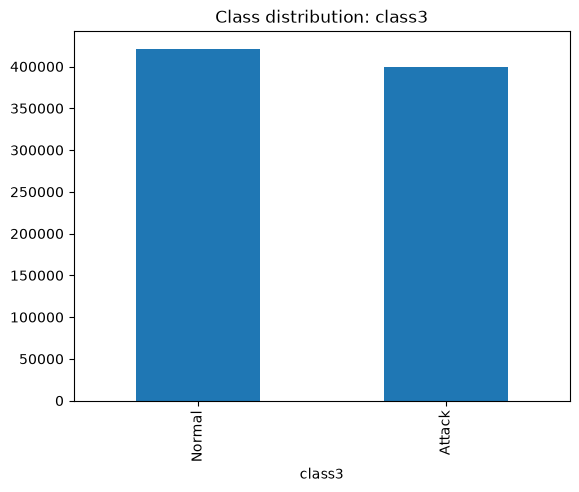

In [8]:
df["class3"].value_counts().plot(kind="bar", title="Class distribution: class3")

In [9]:
df["class3"].value_counts(normalize=True).round(4)

class3
Normal    0.5134
Attack    0.4866
Name: proportion, dtype: float64

**Q5.** How are missing values marked in this dataset, and how many are there?

In [10]:
# Empty fields are written as "-" (and "?" in Protocol), so turn them into real NaN
df = df.replace(["-", "?"], np.nan)

In [11]:
# Feature columns that should be numbers but were read as text because of the "-"
text_cols = ["Date", "Timestamp", "Scr_IP", "Scr_port", "Des_IP", "Des_port", "Protocol", "Service", "anomaly_alert",
             "class1", "class2", "class3"]
num_cols = [col for col in df.columns if col not in text_cols]

# errors="coerce": a few broken cells ("#DIV/0!", "excel", "aza") also become NaN
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage[missing_percentage > 0].sort_values(ascending=False).round(2)

Des_bytes_ratio     27.27
Scr_bytes_ratio     27.27
byte_rate           27.27
total_bytes         27.27
Des_bytes           27.27
Scr_bytes           27.27
paket_rate          27.27
Scr_ip_bytes        18.61
Scr_packts_ratio    18.61
Des_pkts_ratio      18.61
total_packet        18.61
Scr_pkts            18.61
Des_pkts            18.61
Des_ip_bytes        18.61
Duration             9.23
Std_kbmemused        0.14
Avg_kbmemused        0.14
Std_ldavg_1          0.06
Avg_ldavg_1          0.06
Avg_user_time        0.06
Std_wtps             0.06
Std_rtps             0.06
Avg_tps              0.06
Std_tps              0.06
Avg_rtps             0.06
Avg_wtps             0.06
Avg_system_time      0.06
Avg_iowait_time      0.06
Std_iowait_time      0.06
Std_system_time      0.06
Avg_nice_time        0.06
Std_nice_time        0.06
Std_ideal_time       0.06
Std_user_time        0.06
Avg_ideal_time       0.06
Avg_num_Proc/s       0.06
Avg_num_cswch/s      0.06
Std_num_proc/s       0.06
std_num_cswc

## 4. Clean the data
**Q6.** Which columns have the same value in every row? Drop them.

In [13]:
# A column with only one value cannot help the tree split anything
constant_cols = [col for col in df.columns if df[col].nunique(dropna=False) == 1]
constant_cols

['Bad_checksum', 'is_SYN_with_RST']

In [14]:
df = df.drop(columns=constant_cols)
df.shape

(820834, 66)

**Q7.** Drop the identifier columns. Why do they cause overfitting?

In [15]:
# Date/time, IP addresses and ports identify one capture, not the attack itself
id_cols = ["Date", "Timestamp", "Scr_IP", "Scr_port", "Des_IP", "Des_port"]
df = df.drop(columns=id_cols)
df.shape

(820834, 60)

**Q8.** How many duplicate rows are there now?

In [16]:
no_of_duplicates = df.duplicated().sum()
no_of_duplicates

np.int64(119685)

In [17]:
if DEDUPLICATE:
    df = df.drop_duplicates().reset_index(drop=True)
df.shape

(820834, 60)

## 5. Targets and split
**Q9.** Build the features `X` and the target `y` (`class3`), then split 80/20 with stratification. Do the class shares match between train and test?

In [18]:
# All three targets leave the features, otherwise the model would just read the answer
X = df.drop(columns=["class1", "class2", "class3"])
# Attack = 1 (the positive class), Normal = 0
y = (df["class3"] == "Attack").astype(int)

# Stratify on class1 (the finest labels) in all three notebooks, so every model uses the exact same rows
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=df["class1"])
X_train.shape, X_test.shape

((656667, 57), (164167, 57))

In [19]:
# Class shares should be (almost) the same in train and test
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).round(4)

,train,test
class3,,
0,0.5134,0.5134
1,0.4866,0.4866


## 6. Encode the features
**Q10.** Encode the features. Why are the encoders fitted after the split? Why is no scaling needed for trees?

In [20]:
onehot_cols = ["Protocol", "Service", "anomaly_alert"]

X_train = X_train.copy()
X_test = X_test.copy()

# Missing text values become their own category
for col in onehot_cols:
    X_train[col] = X_train[col].fillna("missing")
    X_test[col] = X_test[col].fillna("missing")

# Missing numbers become -1: no real value here is negative, so the tree can split "missing" apart
X_train = X_train.fillna(-1)
X_test = X_test.fillna(-1)

# Columns come from the training set; the test set is lined up to them (unseen categories dropped, missing ones = 0)
X_train = pd.get_dummies(X_train, columns=onehot_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=onehot_cols, dtype=int).reindex(columns=X_train.columns, fill_value=0)

# No scaling: a tree only compares a feature with a threshold, so the scale does not matter
X_train.shape, X_test.shape

((656667, 78), (164167, 78))

## 7. Validation with stratified 5-fold
**Q11.** Run stratified 5-fold validation with the fixed hyperparameters. Is the validation score stable across the folds?

In [21]:
# 5 rounds on the 80%: each round trains on 4 parts (64% of all data) and validates on 1 part (16%)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_scores = []
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    m = DecisionTreeClassifier(**HP)
    m.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    pred = m.predict(X_train.iloc[val_idx])
    fold_scores.append({"fold": fold,
                        "val_accuracy": accuracy_score(y_train.iloc[val_idx], pred),
                        "val_f1": f1_score(y_train.iloc[val_idx], pred)})

fold_df = pd.DataFrame(fold_scores).set_index("fold")
fold_df.round(4)

,val_accuracy,val_f1
fold,,
1,0.9955,0.9953
2,0.9955,0.9953
3,0.9956,0.9955
4,0.9955,0.9954
5,0.9956,0.9955


In [22]:
# Mean and spread over the 5 folds (small std = stable model)
fold_df.agg(["mean", "std"]).round(4)

,val_accuracy,val_f1
mean,0.9955,0.9954
std,0.0001,0.0001


## 8. Final model
**Q12.** Train the final model on the full training set. How long does it take? How deep is the tree, and how many leaves does it have?

In [23]:
model = DecisionTreeClassifier(**HP)

start = time.perf_counter()
model.fit(X_train, y_train)
train_time = time.perf_counter() - start

train_time, model.get_depth(), model.get_n_leaves()

(38.61753449999378, 38, np.int64(2130))

## 9. Evaluation on the test set (used more than once: `max_depth` was revised after the first test results)
**Q13.** Predict on the test set and measure the inference latency (ms per sample).

In [24]:
# Latency = predict() time on the whole test set / number of test rows, in ms per sample
start = time.perf_counter()
y_pred = model.predict(X_test)
latency_ms = (time.perf_counter() - start) / len(X_test) * 1000

# Probabilities are needed for ROC-AUC and Log-Loss
y_proba = model.predict_proba(X_test)
latency_ms

0.0009328403393649332

**Q14.** Compute Accuracy, Precision, Recall, F1, ROC-AUC, Log-Loss, FPR, MCC and TP/TN/FP/FN.

In [25]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba[:, 1])   # column 1 = probability of "attack"
logloss = log_loss(y_test, y_proba)
mcc = matthews_corrcoef(y_test, y_pred)

# ravel() unpacks the 2x2 matrix in this order: TN, FP, FN, TP
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
fpr = fp / (fp + tn)   # share of normal traffic wrongly flagged as attack

pd.Series({"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1,
           "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc}).round(4)

Accuracy     0.9958
Precision    0.9954
Recall       0.9959
F1           0.9957
ROC-AUC      0.9958
Log-Loss     0.1526
FPR          0.0044
MCC          0.9915
dtype: float64

In [26]:
tp, tn, fp, fn

(np.int64(79557), np.int64(83915), np.int64(368), np.int64(327))

**Q15.** Compare the train and test accuracy. Is the tree overfitting or underfitting?

In [27]:
# Train much higher than test = overfitting; both low and close = underfitting
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
round(train_acc, 4), round(test_acc, 4)

(1.0, 0.9958)

## 10. Visualizations
**Q16.** Plot the confusion matrix and the ROC curve.

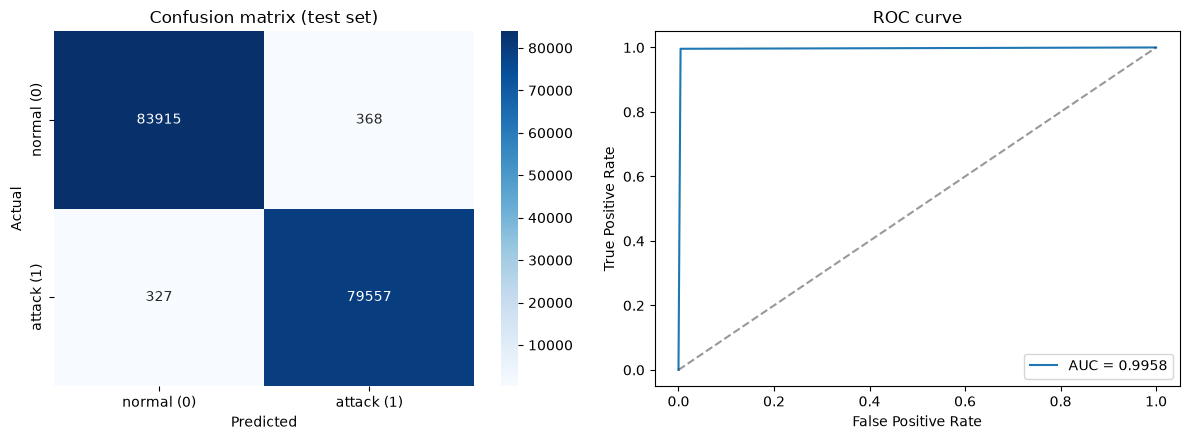

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["normal (0)", "attack (1)"], yticklabels=["normal (0)", "attack (1)"])
ax[0].set(title="Confusion matrix (test set)", xlabel="Predicted", ylabel="Actual")

fpr_curve, tpr_curve, _ = roc_curve(y_test, y_proba[:, 1])
ax[1].plot(fpr_curve, tpr_curve, label=f"AUC = {roc_auc:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)   # a random guess would follow this line
ax[1].set(title="ROC curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
ax[1].legend()

plt.tight_layout()
plt.show()

**Q17.** Which features matter most to the tree?

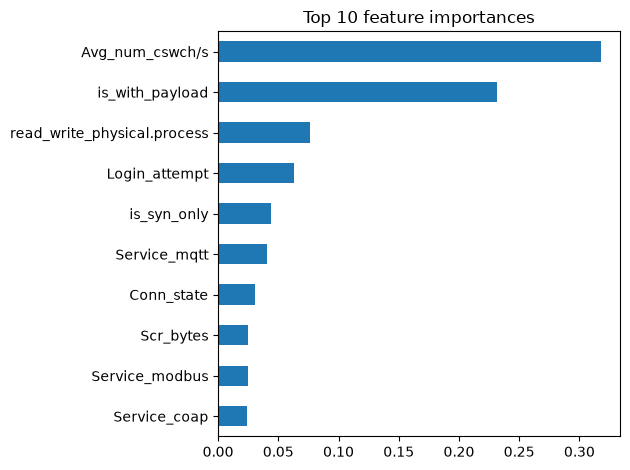

In [29]:
# How much each feature reduced the gini impurity in total (they sum to 1)
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.head(10).sort_values().plot(kind="barh", title="Top 10 feature importances")
plt.tight_layout()
plt.show()

In [30]:
importances.head(10).round(4)

Avg_num_cswch/s                0.3178
is_with_payload                0.2314
read_write_physical.process    0.0766
Login_attempt                  0.0634
is_syn_only                    0.0441
Service_mqtt                   0.0405
Conn_state                     0.0304
Scr_bytes                      0.0247
Service_modbus                 0.0247
Service_coap                   0.0243
dtype: float64

**Q18.** Plot the top levels of the tree. Do the first splits make sense for network attacks?

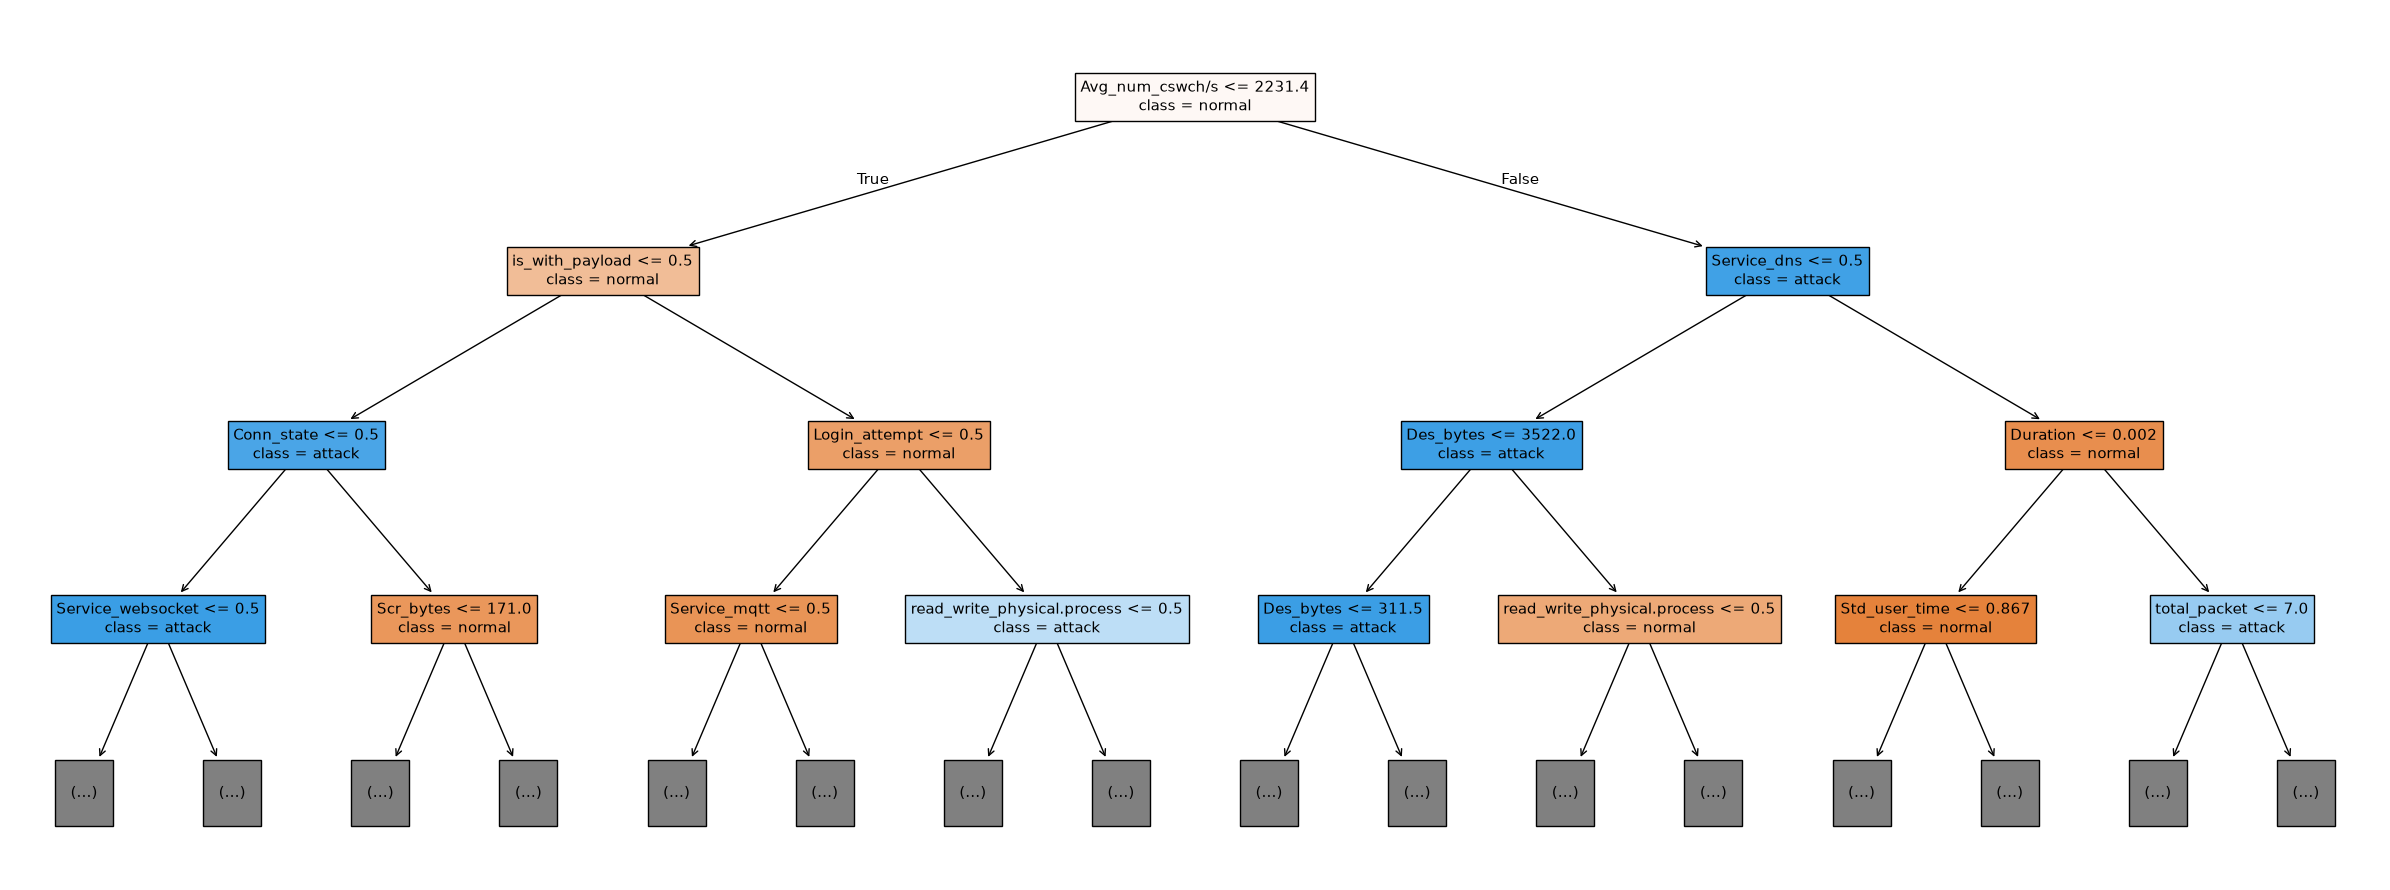

In [31]:
# Only the first 3 levels of the tree
fig, ax = plt.subplots(figsize=(24, 9))
nodes = plot_tree(model, feature_names=list(X_train.columns), class_names=["normal", "attack"], filled=True,
                  max_depth=3, impurity=False, fontsize=11, ax=ax)

# Keep only the split question and the predicted class in each box;
# the "samples" and "value = [...]" lines make the boxes too wide and they overlap
for node in nodes:
    text = node.get_text()
    if "value" in text:
        keep = [line for line in text.splitlines() if "<=" in line or line.startswith("class")]
        node.set_text("\n".join(keep))

plt.tight_layout()
plt.show()

## 11. Results table
**Q19.** Collect all the numbers in one results table.

In [32]:
results = pd.DataFrame([{
    "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-Score": f1,
    "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc,
    "Inference Latency (ms/sample)": latency_ms, "Training time (s)": train_time,
    "TP": tp, "TN": tn, "FP": fp, "FN": fn,
    "Test rows": len(y_test),
}], index=["Decision Tree - X-IIoTID class3"])
results.T

,Decision Tree - X-IIoTID class3
Accuracy,0.995767
Precision,0.995396
Recall,0.995907
F1-Score,0.995651
ROC-AUC,0.995770
Log-Loss,0.152591
FPR,0.004366
MCC,0.991527
Inference Latency (ms/sample),0.000933
Training time (s),38.617534


## 12. Discussion (for the report)
**Q20.** How does this model compare with the KNN, Random Forest and XGBoost results?

**Q21.** Which kind of error matters more here, false positives or false negatives?

**Q22.** What are the limitations of this model?

**Your notes:**